# Income Prediction: Pipelines, Cross-Validation and Six Models
Predict whether a person earns **more than $50K a year** from 1994 US census data (UCI *Adult*). The focus is on doing model comparison properly: one leak-free `Pipeline` per model, stratified cross-validation, and a fair comparison of Logistic Regression, Random Forest, Gradient Boosting, XGBoost, LightGBM and CatBoost — followed by SHAP to explain the best boosting model.

**Data:** 48,842 people, 14 attributes.  
**Metrics:** ROC-AUC (ranking quality) and F1 for the >50K class (only ~24% of people), plus training time.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, shap
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
sns.set_theme(style='whitegrid'); SEED = 42

## 1. Load the data
OpenML hosts a clean copy of UCI Adult (train + test files combined).

In [2]:
raw = fetch_openml('adult', version=2, as_frame=True, data_home='data').frame
print(raw.shape)
raw.dtypes.to_frame('dtype').T

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
dtype,int64,category,int64,category,int64,category,category,category,category,category,int64,int64,int64,category,category


In [3]:
print(raw['class'].value_counts(normalize=True).round(3))
raw.isna().sum()[lambda s: s > 0]

class
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


workclass         2799
occupation        2809
native-country     857
dtype: int64

- Classes are imbalanced (24% earn >50K), so accuracy alone is misleading — I track F1 and ROC-AUC.
- Missing values only in `workclass`, `occupation` and `native-country` (people who didn't answer). Instead of imputing the most frequent value, I keep them as an explicit **"Unknown"** category — not answering can itself be informative.

## 2. Cleaning
- Column names with hyphens (`education-num`) are renamed to `education_num` etc.
- `fnlwgt` is a census *sampling weight* — how many people a row represents — not a property of the person, so it is dropped.
- `education_num` is just an ordinal code of `education`, so only one of them is kept (`education`).
- Category codes like `Married-civ-spouse` or `Exec-managerial` are mapped to readable words for the web form (mapping in `train.py`).

In [4]:
from train import load_data   # same cleaning as the production script
%matplotlib inline
X, y = load_data()
print(X.shape, '| positive rate:', round(y.mean(), 3))
X.head()

(48842, 12) | positive rate: 0.239


,age,workclass,education,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,25.0,Private company,Grade 11,Never married,Machine operator,Own child,Black,Male,0.0,0.0,40.0,United States
1,38.0,Private company,High school graduate,Married,Farming / fishing,Spouse (male),White,Male,0.0,0.0,50.0,United States
2,28.0,Local government,Associate (academic),Married,Protective service,Spouse (male),White,Male,0.0,0.0,40.0,United States
3,44.0,Private company,Some college,Married,Machine operator,Spouse (male),Black,Male,7688.0,0.0,40.0,United States
4,18.0,Unknown,Some college,Never married,Unknown,Own child,White,Female,0.0,0.0,30.0,United States


## 3. Exploratory analysis

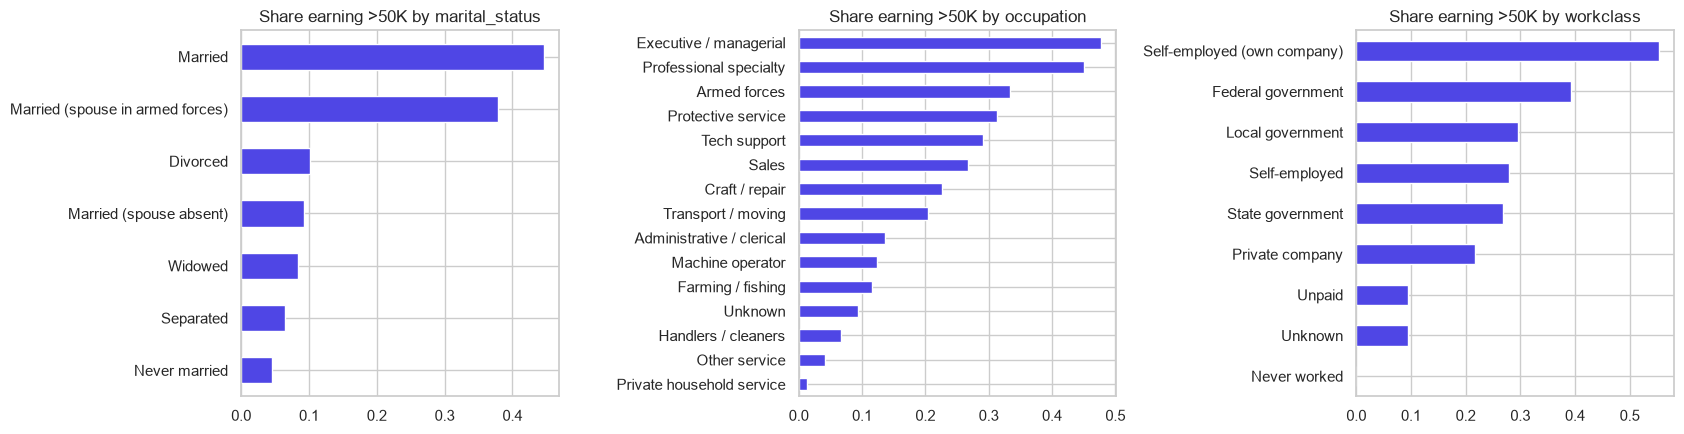

In [5]:
df = X.assign(high_income=y)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ['marital_status', 'occupation', 'workclass']):
    df.groupby(col)['high_income'].mean().sort_values().plot.barh(ax=ax, color='#4f46e5')
    ax.set_title(f'Share earning >50K by {col}'); ax.set_ylabel('')
plt.tight_layout()

People with any capital gain: 8.3% | their >50K rate: 61.7%


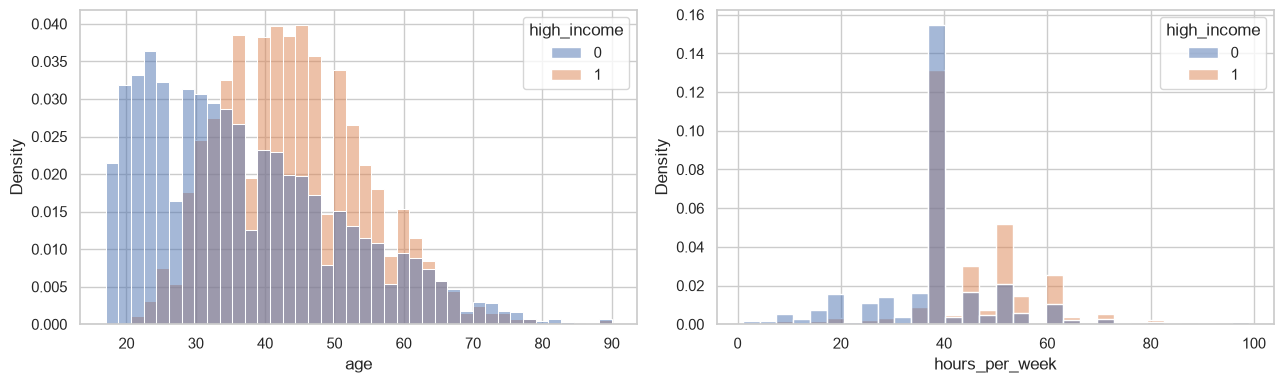

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='age', hue='high_income', bins=40, stat='density', common_norm=False, ax=axes[0])
sns.histplot(data=df, x='hours_per_week', hue='high_income', bins=30, stat='density', common_norm=False, ax=axes[1])
plt.tight_layout()
print('People with any capital gain:', f"{(df.capital_gain > 0).mean():.1%}",
      '| their >50K rate:', f"{df.loc[df.capital_gain > 0, 'high_income'].mean():.1%}")

**Findings**
- Married people (spouses in a household) earn >50K far more often than never-married people.
- Executive/managerial and professional occupations have the highest rates; private-household service the lowest.
- High earners are older (peak in the 40s–50s) and work longer hours.
- Capital gains are rare but a very strong signal.

## 4. Pipelines and a leak-free split
The test set (20%, stratified) is kept aside. Every model is a single `Pipeline`, so scaling and one-hot encoding are re-fitted inside each CV fold — fitting the preprocessor on all data first would leak information from validation folds.

One-hot output is **dense** on purpose: XGBoost/LightGBM treat zeros in a *sparse* matrix as missing values, which would make the exported ONNX model (which sees real zeros) disagree with Python. Tree models also get the raw numbers (no scaling): trees don't need it, and scaled float64 values can fall on the other side of a split after the float32 rounding used by ONNX.

In [7]:
num_cols = ['age', 'capital_gain', 'capital_loss', 'hours_per_week']
cat_cols = [c for c in X.columns if c not in num_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
def prep(scale=False):   # trees don't need scaling; only the linear model gets it
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', num_cols),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(X_train.shape, X_test.shape)

(39073, 12) (9769, 12)


### Tuning the baseline
Logistic regression's regularisation strength, tuned by grid search inside CV:

In [8]:
grid = GridSearchCV(Pipeline([('prep', prep(scale=True)), ('model', LogisticRegression(max_iter=2000))]),
                    {'model__C': [0.01, 0.1, 1, 10]}, scoring='roc_auc', cv=cv, n_jobs=1)
grid.fit(X_train, y_train)
pd.DataFrame(grid.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score']].round(4)

,param_model__C,mean_test_score,std_test_score
0,0.01,0.9020,0.0039
1,0.10,0.9061,0.0038
2,1.00,0.9064,0.0038
3,10.00,0.9063,0.0038


Regularisation barely matters here (C ≥ 0.1 is flat), so C = 1 is kept.

## 5. Comparing six models
Same folds for every model, single-threaded so training times are comparable. To keep this notebook quick to re-run, the comparison here uses 3-fold CV on a stratified half of the training set; `train.py` runs the full 5-fold CV on all 39k training rows (those numbers are in the README and the web demo). CatBoost gets the raw categorical columns (it encodes them itself); CatBoost's `cat_features` parameter does not survive scikit-learn's `clone()`, so it uses a manual CV loop over the same folds.

In [9]:
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=0.5, stratify=y_train, random_state=SEED)
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
pipe = lambda m: Pipeline([('prep', prep()), ('model', m)])
models = {
    'Logistic Regression': Pipeline([('prep', prep(scale=True)), ('model', LogisticRegression(max_iter=2000, C=1.0))]),
    'Random Forest': pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=1)),
    'Gradient Boosting': pipe(GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=4, subsample=0.6, random_state=SEED)),
    'XGBoost': pipe(XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=1)),
    'LightGBM': pipe(LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                    colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbose=-1)),
}
cb_params = dict(iterations=500, depth=6, learning_rate=0.08, random_seed=SEED, cat_features=cat_cols,
                 verbose=False, allow_writing_files=False, thread_count=1)

rows = []
for name, model in models.items():
    r = cross_validate(model, X_cv, y_cv, cv=cv3, n_jobs=1, scoring=['roc_auc', 'f1', 'accuracy'])
    rows.append({'model': name, 'ROC-AUC': r['test_roc_auc'].mean(), 'F1': r['test_f1'].mean(),
                 'Accuracy': r['test_accuracy'].mean(), 'fit time (s)': r['fit_time'].mean()})
auc, f1, acc, t = [], [], [], []
for tr, va in cv3.split(X_cv, y_cv):
    t0 = time.perf_counter(); cb = CatBoostClassifier(**cb_params).fit(X_cv.iloc[tr], y_cv.iloc[tr]); t.append(time.perf_counter() - t0)
    p = cb.predict_proba(X_cv.iloc[va])[:, 1]; yv = y_cv.iloc[va]
    auc.append(roc_auc_score(yv, p)); f1.append(f1_score(yv, p >= 0.5)); acc.append(accuracy_score(yv, p >= 0.5))
rows.append({'model': 'CatBoost', 'ROC-AUC': np.mean(auc), 'F1': np.mean(f1), 'Accuracy': np.mean(acc), 'fit time (s)': np.mean(t)})
results = pd.DataFrame(rows).set_index('model').sort_values('ROC-AUC', ascending=False)
results.round(4)

,ROC-AUC,F1,Accuracy,fit time (s)
model,,,,
CatBoost,0.9237,0.6979,0.8679,55.8786
XGBoost,0.9227,0.7021,0.8677,4.8877
Gradient Boosting,0.9209,0.6927,0.8666,18.9666
LightGBM,0.9201,0.6994,0.8653,1.8399
Random Forest,0.9127,0.6637,0.8578,9.7765
Logistic Regression,0.9052,0.6546,0.8502,0.6089


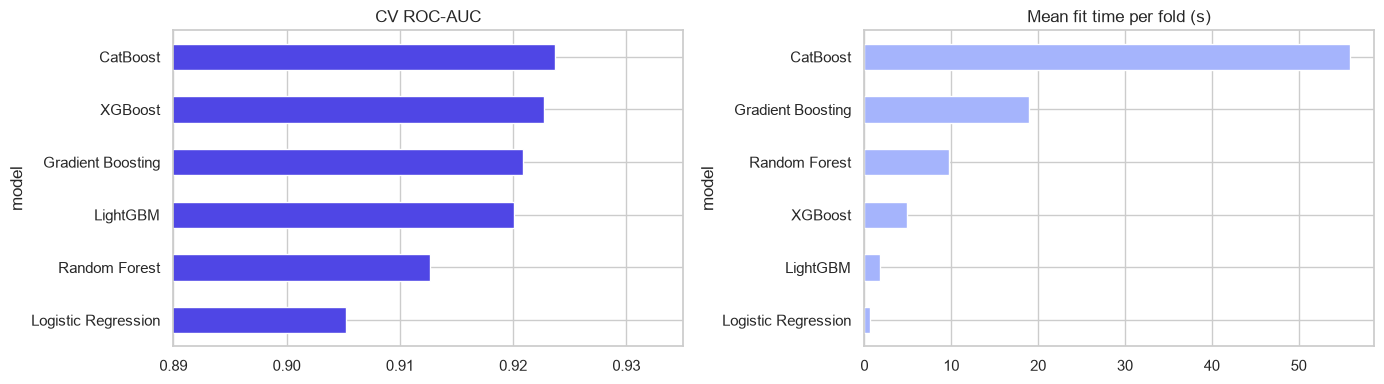

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
results['ROC-AUC'].sort_values().plot.barh(ax=axes[0], color='#4f46e5', xlim=(0.89, 0.935), title='CV ROC-AUC')
results['fit time (s)'].sort_values().plot.barh(ax=axes[1], color='#a5b4fc', title='Mean fit time per fold (s)')
plt.tight_layout()

- The **gradient-boosted trees (XGBoost, LightGBM, CatBoost)** are clearly ahead of Logistic Regression and Random Forest, and they are within a few thousandths of each other.
- **LightGBM is the fastest** of the strong models; scikit-learn's classic Gradient Boosting is several times slower than LightGBM and XGBoost (and weaker than them on the full training data in `train.py`).
- The demo model must run in the browser, so it has to be convertible to ONNX together with its preprocessing. XGBoost and LightGBM pipelines convert (via `onnxmltools`); CatBoost's native categorical handling does not fit in a scikit-learn ONNX graph. `train.py` therefore ships the best *exportable* pipeline.

## 6. Explaining the best boosting model with SHAP

Best boosting model by CV ROC-AUC: CatBoost


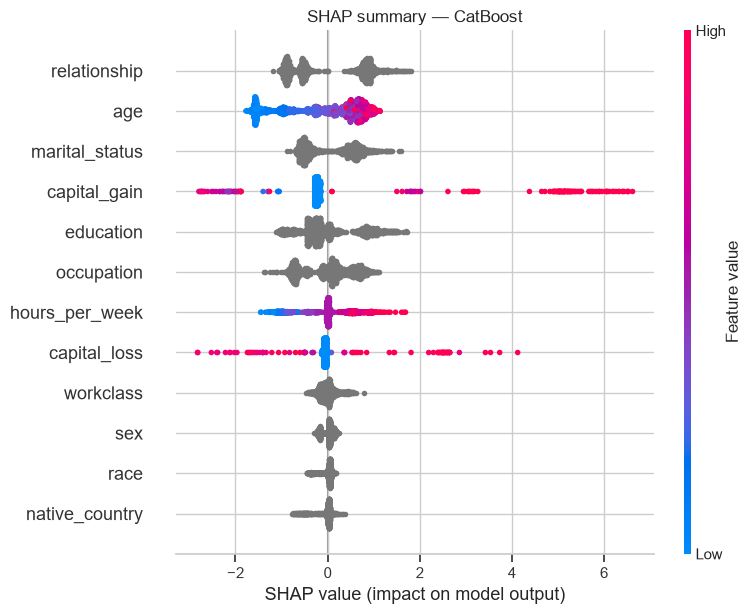

In [11]:
boosters = [m for m in results.index if m in ('XGBoost', 'LightGBM', 'CatBoost')]
best_boost = boosters[0]; print('Best boosting model by CV ROC-AUC:', best_boost)
sample = X_test.sample(2000, random_state=SEED)
if best_boost == 'CatBoost':
    model = CatBoostClassifier(**{**cb_params, 'thread_count': -1}).fit(X_train, y_train)
    Z, names = sample, list(sample.columns)
    sv = shap.TreeExplainer(model).shap_values(sample)
else:
    model = models[best_boost].fit(X_train, y_train)
    Z = model[0].transform(sample)
    names = [n.split('__', 1)[1] for n in model[0].get_feature_names_out()]
    sv = shap.TreeExplainer(model[-1]).shap_values(Z)
sv = sv[1] if isinstance(sv, list) else sv
features = Z if best_boost == 'CatBoost' else pd.DataFrame(Z, columns=names)
shap.summary_plot(sv, features, max_display=15, show=False)
plt.title(f'SHAP summary — {best_boost}'); plt.tight_layout()

Each dot is one person; position = how much that feature pushed the prediction towards >50K (right) or ≤50K (left). For numeric features the colour shows the value: older age, longer working hours and capital gains push towards >50K. Categorical features (grey) — household role, marital status, education and occupation — are among the strongest drivers; their direction matches the EDA above (married people and managerial/professional occupations earn more).

## 7. Final evaluation on the test set
The shipped model is evaluated once on the untouched 20% test set:

Shipped model: XGBoost


Test ROC-AUC: 0.9305
              precision    recall  f1-score   support

       <=50K      0.898     0.946     0.922      7431
        >50K      0.794     0.658     0.720      2338

    accuracy                          0.877      9769
   macro avg      0.846     0.802     0.821      9769
weighted avg      0.873     0.877     0.873      9769



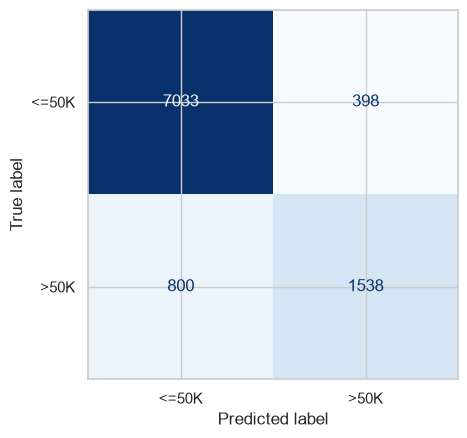

In [12]:
import json
meta = json.load(open('web/meta.json', encoding='utf-8'))
final_name = meta['model_name']; print('Shipped model:', final_name)
final = models[final_name].fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
print('Test ROC-AUC:', round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, proba >= 0.5, target_names=['<=50K', '>50K'], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, proba >= 0.5, display_labels=['<=50K', '>50K'], cmap='Blues', colorbar=False);

### Threshold
The default 0.5 threshold favours precision. If finding high earners matters more (e.g. targeting a premium product), a lower threshold raises recall and F1:

In [13]:
from sklearn.metrics import precision_score, recall_score
pd.DataFrame([{'threshold': t, 'precision': precision_score(y_test, proba >= t), 'recall': recall_score(y_test, proba >= t),
               'F1': f1_score(y_test, proba >= t)} for t in [0.3, 0.4, 0.5, 0.6]]).round(3)

,threshold,precision,recall,F1
0,0.3,0.650,0.821,0.725
1,0.4,0.728,0.734,0.731
2,0.5,0.794,0.658,0.720
3,0.6,0.848,0.575,0.686


## 8. Conclusions
- Gradient-boosted trees win on this tabular problem (CV ROC-AUC ≈ 0.93 vs 0.91 for logistic regression).
- XGBoost, LightGBM and CatBoost are practically tied; LightGBM trains fastest.
- Marital status / household role, capital gains, education, age and hours worked drive the prediction.
- Caveat: 1994 census data reflects historical inequalities (e.g. by sex and race); a model like this should not be used for real decisions about people.

`train.py` reproduces the comparison, exports the best ONNX-convertible pipeline and powers the web demo.